# 6.11 다항 회귀 차수와 훈련·검증 오차

nonlinear.csv는 100행입니다. 난수 시드 42의 교육용 합성 비선형 회귀. 실제 측정값 아님. x 입력, y=sin(1.5x)+잡음. 다항식 차수와 과적합 비교. 단위 없음.

선정 이유: 모델 복잡도 변화가 함수 형태와 훈련·검증 오차에 어떤 영향을 주는지 연결한다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 PolynomialFeatures 기능, 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 릿지 회귀(Ridge Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 평균제곱오차(Mean Squared Error) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.model_selection import train_test_split

# 가져오기(Import) 문장으로 PolynomialFeatures 기능, 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.preprocessing import PolynomialFeatures,StandardScaler

# 가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.pipeline import make_pipeline

# 가져오기(Import) 문장으로 릿지 회귀(Ridge Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.linear_model import Ridge

# 가져오기(Import) 문장으로 평균제곱오차(Mean Squared Error) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.metrics import mean_squared_error

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_11_polynomial_complexity"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.

변수 rows를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 grid를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 axes[0].scatter(X.iloc[tr,0],y.iloc[tr],s=12,facecolors="none",edgecolors="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for degree,style in zip([1,3,12],["-","--",":"]):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.

변수 r를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 r.to_csv(OUT/"polynomial_complexity.csv",index=False) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
f=pd.read_csv(DATA/"nonlinear.csv")

# 입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
X=f[["x"]]

# 목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
y=f.y

# 훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.
tr,va=train_test_split(np.arange(len(f)),test_size=.35,random_state=42)

# 변수 rows를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
rows=[]

# 변수 grid를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
grid=pd.DataFrame({"x":np.linspace(-3,3,200)})

# 변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig,axes=plt.subplots(1,2,figsize=(7.2,3.7))

# 앞 셀의 값을 사용해 axes[0].scatter(X.iloc[tr,0],y.iloc[tr],s=12,facecolors="none",edgecolors="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].scatter(X.iloc[tr,0],y.iloc[tr],s=12,facecolors="none",edgecolors="black")

# 반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for degree,style in zip([1,3,12],["-","--",":"]):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.
for degree,style in zip([1,3,12],["-","--",":"]):
    model=make_pipeline(PolynomialFeatures(degree,include_bias=False),
        StandardScaler(),Ridge(alpha=.01))
    model.fit(X.iloc[tr],y.iloc[tr])
    rows.append({"degree":degree,"train_mse":mean_squared_error(y.iloc[tr],model.predict(X.iloc[tr])),
        "validation_mse":mean_squared_error(y.iloc[va],model.predict(X.iloc[va]))})
    axes[0].plot(grid.x,model.predict(grid),style,color="black",label=f"Degree {degree}")

# 변수 r를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
r=pd.DataFrame(rows)

# 앞 셀의 값을 사용해 r.to_csv(OUT/"polynomial_complexity.csv",index=False) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
r.to_csv(OUT/"polynomial_complexity.csv",index=False)

## 셀 6 입력·계산·출력 확인

앞 셀의 값을 사용해 axes[0].set(xlabel="x",ylabel="y",ylim=(-2.5,2.5)) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[0].legend(fontsize=8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].plot(r.degree,r.train_mse,"ko-",label="Train") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].plot(r.degree,r.validation_mse,"ks--",label="Validation") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].set(xlabel="Degree",ylabel="MSE") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].legend(fontsize=8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "train_n": 65,
  "validation_n": 35,
  "comparison": [
    {
      "degree": 1,
      "train_mse": 0.5473315381283144,
      "validation_mse": 0.5837276886715528
    },
    {
      "degree": 3,
      "train_mse": 0.09840338772961127,
      "validation_mse": 0.10333037320461691
    },
    {
      "degree": 12,
      "train_mse": 0.0555680496892883,
      "validation_mse": 0.07235448274809285
    }
  ]
}


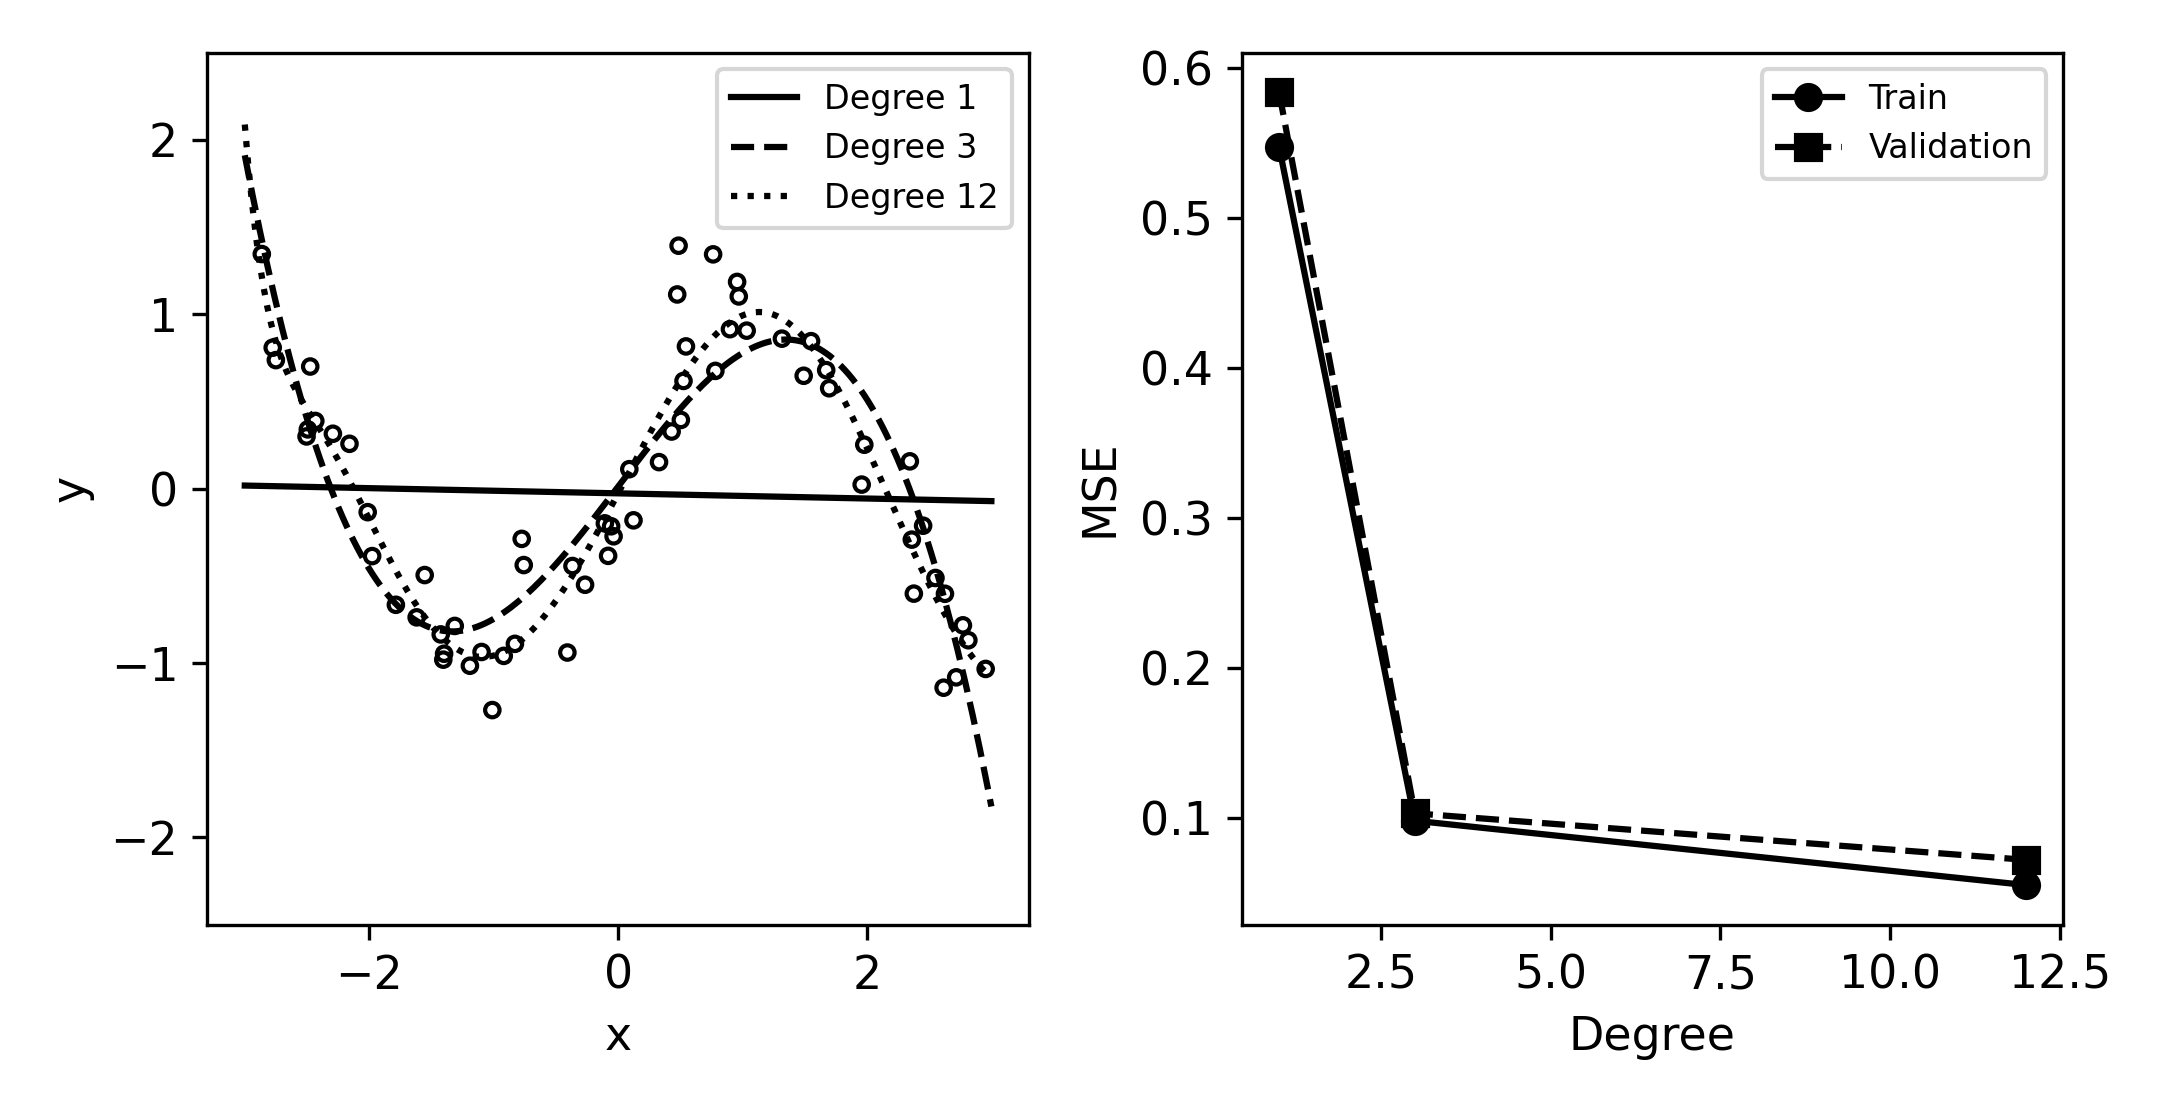

In [6]:
# 앞 셀의 값을 사용해 axes[0].set(xlabel="x",ylabel="y",ylim=(-2.5,2.5)) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].set(xlabel="x",ylabel="y",ylim=(-2.5,2.5))

# 앞 셀의 값을 사용해 axes[0].legend(fontsize=8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].legend(fontsize=8)

# 앞 셀의 값을 사용해 axes[1].plot(r.degree,r.train_mse,"ko-",label="Train") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].plot(r.degree,r.train_mse,"ko-",label="Train")

# 앞 셀의 값을 사용해 axes[1].plot(r.degree,r.validation_mse,"ks--",label="Validation") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].plot(r.degree,r.validation_mse,"ks--",label="Validation")

# 앞 셀의 값을 사용해 axes[1].set(xlabel="Degree",ylabel="MSE") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].set(xlabel="Degree",ylabel="MSE")

# 앞 셀의 값을 사용해 axes[1].legend(fontsize=8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].legend(fontsize=8)

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"polynomial_complexity")

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"polynomial_complexity",{"train_n":len(tr),"validation_n":len(va),
    "comparison":rows})

## 그림과 결과 해석

곡선은 같은 훈련 자료로 학습했다. 차수 12가 반드시 과적합한다는 결론을 미리 정하지 않고 실제 검증 오차를 비교한다.

이 분할은 모델 선택에 쓰는 검증 세트다. 최종 테스트 세트가 아니며 가장 좋은 차수를 고른 뒤의 일반화 성능은 별도 평가해야 한다.